In [2]:
from pathlib import Path
import pandas as pd

# Get the project root folder
PROJECT_ROOT = Path.cwd().parent

# Define file paths
RAW_DATA_PATH = PROJECT_ROOT / "ChargingRecords.csv"
PROCESSED_DATA_PATH = (
    PROJECT_ROOT / "Processed Data" / "ev_charging_cleaned.csv"
)

df = pd.read_csv(RAW_DATA_PATH)

df.head()
df.shape
df.columns
df.info()

df[['Demand', 'Duration']].describe()

<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 12.5 MB


,Demand,Duration
count,72856.000000,72856.000000
mean,17.444445,151.194054
std,13.492728,146.430286
min,0.010000,-29.000000
25%,7.530000,40.000000
50%,14.100000,112.000000
75%,23.200000,202.000000
max,97.000000,1573.000000


In [3]:
print((df['Duration'] < 0).sum())


17


In [4]:
df[df['Duration'] < 0][
    ['StartDatetime', 'EndDatetime', 'Duration', 'Demand']
].head(10)

,StartDatetime,EndDatetime,Duration,Demand
55422,2022-02-15 15:04,2022-02-15 14:35,-29,11.68
55425,2022-02-24 14:27,2022-02-24 14:18,-9,34.56
55427,2022-01-17 14:47,2022-01-17 14:39,-8,17.77
55455,2022-04-29 18:58,2022-04-29 18:52,-6,31.90
55457,2022-05-07 16:24,2022-05-07 16:03,-21,13.39
55458,2022-04-29 15:48,2022-04-29 15:43,-6,19.36
55459,2022-03-27 15:17,2022-03-27 15:10,-7,20.99
55460,2022-02-05 18:52,2022-02-05 18:50,-2,31.59
55464,2022-05-08 12:02,2022-05-08 11:42,-20,3.28
55465,2022-01-09 14:29,2022-01-09 14:20,-9,31.68


In [5]:
# convert datatypes of date and time
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])
df['EndDatetime'] = pd.to_datetime(df['EndDatetime'])
print(df[['StartDatetime', 'EndDatetime']].dtypes)

#calculate duartion 

df['Calculated_Duration'] = (df['EndDatetime'] - df['StartDatetime']).dt.total_seconds() / 60

print(df[['Duration', 'Calculated_Duration']].head(10))

print((df['Duration'] != df['Calculated_Duration']).sum())

#create new column
df['Duration_Difference'] = (df['Duration'] - df['Calculated_Duration'])

print(df['Duration_Difference'].value_counts().head(10))

display(df['Duration_Difference'].abs().max())

#understand why we have negative value
df.loc[
    df['Duration_Difference'].abs() >= 100,
    ['StartDatetime', 'EndDatetime', 'Duration',
     'Calculated_Duration', 'Duration_Difference', 'Demand']
].head(20)

StartDatetime    datetime64[us]
EndDatetime      datetime64[us]
dtype: object
   Duration  Calculated_Duration
0       185                185.0
1        90                 90.0
2        60                 60.0
3       344                344.0
4       300                300.0
5        70                 70.0
6        60                 60.0
7       494                494.0
8        60                 60.0
9       112                112.0
20751
Duration_Difference
 0.0     52105
-1.0      9680
 1.0      7574
-2.0       930
-31.0      350
-10.0      269
-3.0       261
-32.0      231
-33.0      153
-30.0      112
Name: count, dtype: int64


np.float64(4320.0)

,StartDatetime,EndDatetime,Duration,Calculated_Duration,Duration_Difference,Demand
15,2022-08-19 17:10:00,2022-08-19 19:10:00,4,120.0,-116.0,12.42
246,2021-12-27 17:29:00,2021-12-27 20:24:00,0,175.0,-175.0,17.32
348,2022-03-31 22:46:00,2022-04-01 02:39:00,0,233.0,-233.0,16.87
349,2022-04-14 21:17:00,2022-04-15 00:29:00,0,192.0,-192.0,19.69
364,2022-03-22 10:05:00,2022-03-22 16:19:00,0,374.0,-374.0,39.01
378,2022-02-05 20:55:00,2022-02-06 00:04:00,0,189.0,-189.0,17.81
2153,2022-09-10 03:52:00,2022-09-10 14:09:00,112,617.0,-505.0,11.80
2160,2022-08-20 19:01:00,2022-08-21 05:10:00,165,609.0,-444.0,8.70
2171,2022-02-05 15:54:00,2022-02-05 19:04:00,0,190.0,-190.0,9.10
2185,2021-11-01 19:01:00,2021-11-02 08:28:00,441,807.0,-366.0,51.30


In [6]:
print((df['EndDatetime'] >= df['StartDatetime']).value_counts())

print((df['Calculated_Duration'] < 0).sum())

True     72839
False       17
Name: count, dtype: int64
17


The 17 negative-duration records are caused by invalid timestamp ordering, where EndDatetime occurs before StartDatetime. Instead of removing the 17 records we are creating a new dataframe

In [7]:
df_clean = df[df['Calculated_Duration'] >= 0].copy()
df_clean.shape
display(df_clean['Calculated_Duration'].describe())
display(df_clean['Calculated_Duration'].value_counts().head(10))



count    72839.000000
mean       155.544365
std        159.181424
min          0.000000
25%         41.000000
50%        114.000000
75%        204.000000
max       4717.000000
Name: Calculated_Duration, dtype: float64

Calculated_Duration
40.0    3207
60.0     739
1.0      718
43.0     710
41.0     536
30.0     530
0.0      530
27.0     450
31.0     445
28.0     444
Name: count, dtype: int64

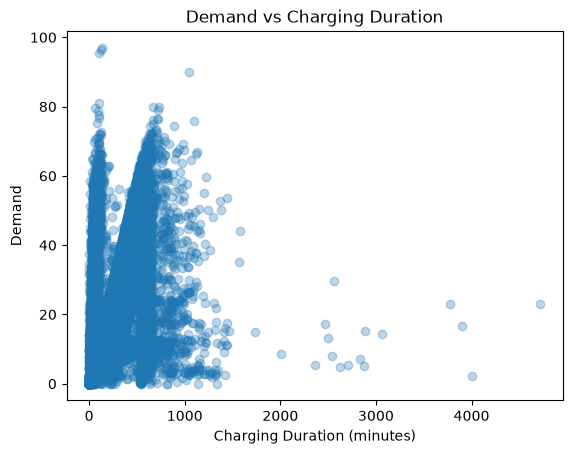

0.900    360.0
0.950    473.0
0.990    656.0
0.995    829.0
Name: Calculated_Duration, dtype: float64

In [8]:
# finding the correlation

df_clean[['Demand', 'Calculated_Duration']].corr()

import matplotlib.pyplot as plt

plt.scatter(
    df_clean['Calculated_Duration'],
    df_clean['Demand'],
    alpha=0.3
)

plt.xlabel('Charging Duration (minutes)')
plt.ylabel('Demand')
plt.title('Demand vs Charging Duration')

plt.show()

df_clean['Calculated_Duration'].quantile([0.90, 0.95, 0.99, 0.995])

In [9]:
bins = [0, 60, 120, 180, 240, 300, float('inf')]

labels = ['0-60', '61-120', '121-180',
          '181-240', '241-300', '301+']

df_clean['Duration_Group'] = pd.cut(
    df_clean['Calculated_Duration'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

duration_demand = df_clean.groupby(
    'Duration_Group',
    observed=True
)['Demand'].mean()

print(duration_demand)

Duration_Group
0-60       11.248016
61-120     11.070916
121-180    15.009276
181-240    19.787120
241-300    26.813592
301+       38.583902
Name: Demand, dtype: float64


# Average EV charging Demand generally increases as charging session duration increases. However, the relationship is not perfectly monotonic because the 61–120 minute group has slightly lower average Demand than the 0–60 minute group.

In [10]:
# Next calculate demand by hour of the day

df_clean['Hour'] = df_clean['StartDatetime'].dt.hour
hourly_demand = df_clean.groupby('Hour')['Demand'].mean()

print(hourly_demand)

Hour
0     26.547193
1     25.319131
2     25.036850
3     20.249701
4     18.259526
5     17.245738
6     17.011564
7     16.827238
8     17.517359
9     14.409591
10    13.420777
11    13.710208
12    13.409559
13    13.703505
14    14.086236
15    14.053455
16    15.557114
17    16.987276
18    18.346443
19    20.001980
20    21.546702
21    22.847293
22    23.796721
23    27.713834
Name: Demand, dtype: float64


# Demand is relatively high during late night/early morning, decreases toward the daytime, reaches its lowest level around noon, and rises again during the evening.

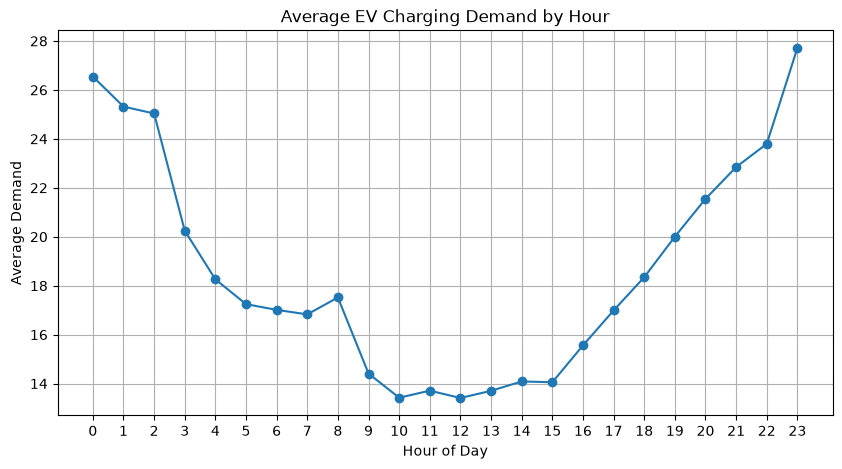

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker='o'
)

plt.xlabel('Hour of Day')
plt.ylabel('Average Demand')
plt.title('Average EV Charging Demand by Hour')
plt.xticks(range(24))
plt.grid(True)

plt.show()

# EV charging demand varies significantly by time of day. Demand is relatively high during late-night and early-morning hours, reaches its lowest level around midday, and increases steadily during the evening, peaking around 23:00. This indicates that the hour of charging is an important factor associated with EV charging demand.

In [12]:
# to find out the demand by weekday/weekends

df_clean['DayOfWeek'] = df_clean['StartDatetime'].dt.dayofweek
daily_demand = df_clean.groupby('DayOfWeek')['Demand'].mean()

print(daily_demand)

DayOfWeek
0    17.352547
1    17.107073
2    17.527834
3    17.625724
4    17.306678
5    17.417148
6    17.806118
Name: Demand, dtype: float64


# Average EV charging demand remains relatively consistent across the days of the week, ranging from approximately 17.11 to 17.81. Sunday records the highest average demand, while Tuesday records the lowest. However, the small variation suggests that day of the week may have a weaker relationship with demand compared with the hour of the day.

In [13]:
# Charger Type vs Demand.
print(df_clean['ChargerType'].value_counts())
charger_demand = df_clean.groupby('ChargerType')['Demand'].mean()

print(charger_demand)

ChargerType
0    57903
1    14936
Name: count, dtype: int64
ChargerType
0    17.054121
1    18.946413
Name: Demand, dtype: float64


# Average charging Demand differs by charger type. Charger Type 1 has a higher average Demand (18.95) compared with Charger Type 0 (17.05), suggesting that charger type may be an important predictor of charging demand.

In [14]:
# to analyze the charger company

print(df_clean['ChargerCompany'].value_counts())
company_demand = df_clean.groupby('ChargerCompany')['Demand'].mean()

print(company_demand)

ChargerCompany
1    45713
0    27126
Name: count, dtype: int64
ChargerCompany
0    16.690071
1    17.888424
Name: Demand, dtype: float64


# Average charging Demand varies between charger companies. Company 1 shows a higher average Demand (17.89) than Company 0 (16.69), suggesting that ChargerCompany may provide useful information for predicting Demand.

In [16]:
#Examine Location

print(df_clean['Location'].nunique())
print(df_clean['Location'].value_counts())

location_demand = (
    df_clean.groupby('Location')['Demand']
    .mean()
    .sort_values(ascending=False)
)

print(location_demand)

14
Location
public area           14082
apartment             14038
resort                 8854
hotel                  8600
company                7558
public institution     7023
public parking lot     3396
market                 2988
restaurant             2222
camping                1630
sightseeing            1203
golf                   1029
accommodation           187
bus garage               29
Name: count, dtype: int64
Location
accommodation         29.055829
bus garage            28.587586
camping               25.525288
apartment             18.746507
public area           17.906683
restaurant            17.813123
public institution    17.399318
resort                17.280838
public parking lot    17.186767
golf                  16.718299
market                16.506272
company               16.247879
sightseeing           15.245129
hotel                 14.704900
Name: Demand, dtype: float64


In [17]:
# charger id

print(df_clean['ChargerID'].nunique())
print(df_clean['UserID'].nunique())

2118
2337


In [18]:
charger_usage = df_clean['ChargerID'].value_counts()

print(charger_usage.describe())
print(charger_usage.head(10))

count    2118.000000
mean       34.390463
std        75.719556
min         1.000000
25%         3.000000
50%         9.000000
75%        26.000000
max       674.000000
Name: count, dtype: float64
ChargerID
573    674
25     658
163    648
95     576
273    576
29     557
3      549
30     530
33     513
19     509
Name: count, dtype: int64


In [19]:
# analyze the target variable
print(df_clean['Demand'].describe())
print(df_clean['Demand'].skew())

count    72839.000000
mean        17.442145
std         13.491897
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64
1.1902124498918036


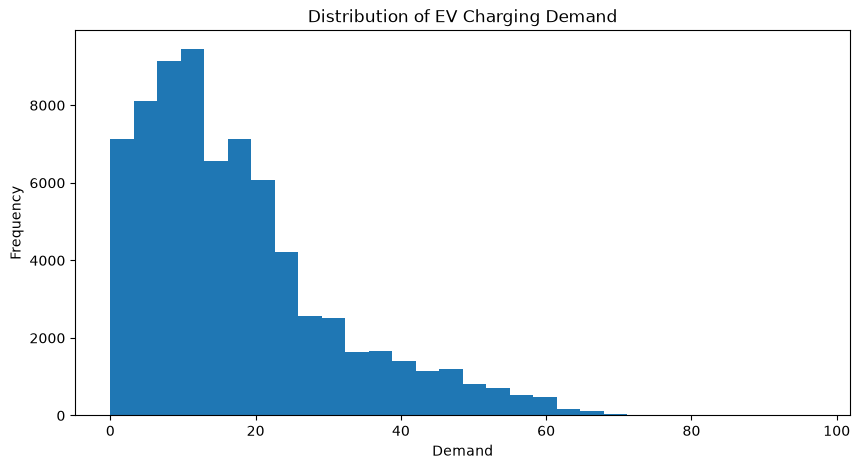

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean['Demand'], bins=30)

plt.xlabel('Demand')
plt.ylabel('Frequency')
plt.title('Distribution of EV Charging Demand')

plt.show()

# Demand is positively skewed, with most observations concentrated at lower demand values and a smaller number of high-demand observations extending the distribution toward 97. These high values should not be removed automatically because they may represent genuine high-demand charging sessions.

In [26]:
# Check missing values
missing_values = df_clean.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values by column:
UserID                 0
ChargerID              0
ChargerCompany         0
Location               0
ChargerType            0
StartDay               0
StartTime              0
EndDay                 0
EndTime                0
StartDatetime          0
EndDatetime            0
Duration               0
Demand                 0
Calculated_Duration    0
Duration_Difference    0
Duration_Group         0
Hour                   0
DayOfWeek              0
dtype: int64

Total missing values: 0


In [27]:
# Check duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 13


In [29]:
duplicate_rows = df_clean[df_clean.duplicated(keep=False)]

print("Duplicate rows including original records:")
print(duplicate_rows)
print("Shape of duplicate records:", duplicate_rows.shape)

Duplicate rows including original records:
       UserID  ChargerID  ChargerCompany            Location  ChargerType  \
28856     329        214               1         public area            0   
28857     329        214               1         public area            0   
28858     329        214               1         public area            0   
28859     329        214               1         public area            0   
28861     329        214               1         public area            0   
28862     329        214               1         public area            0   
40669     461        371               1           apartment            0   
40670     461        371               1           apartment            0   
51498     276        640               0             company            1   
51499     276        640               0             company            1   
56652    1956        854               0         public area            1   
56653    1956        854         

In [30]:
df_clean = df_clean.drop_duplicates().copy()
print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (72826, 18)
Remaining duplicate rows: 0


In [ ]:
df_clean.to_csv(df_clean.to_csv(PROCESSED_DATA_PATH, index=False))

In [ ]:
check_df = pd.read_csv(check_df = pd.read_csv(PROCESSED_DATA_PATH))

print("Saved dataset shape:", check_df.shape)
print("Duplicate rows:", check_df.duplicated().sum())

Saved dataset shape: (72826, 18)
Duplicate rows: 0
